**Lab** **Sheet**-**4**




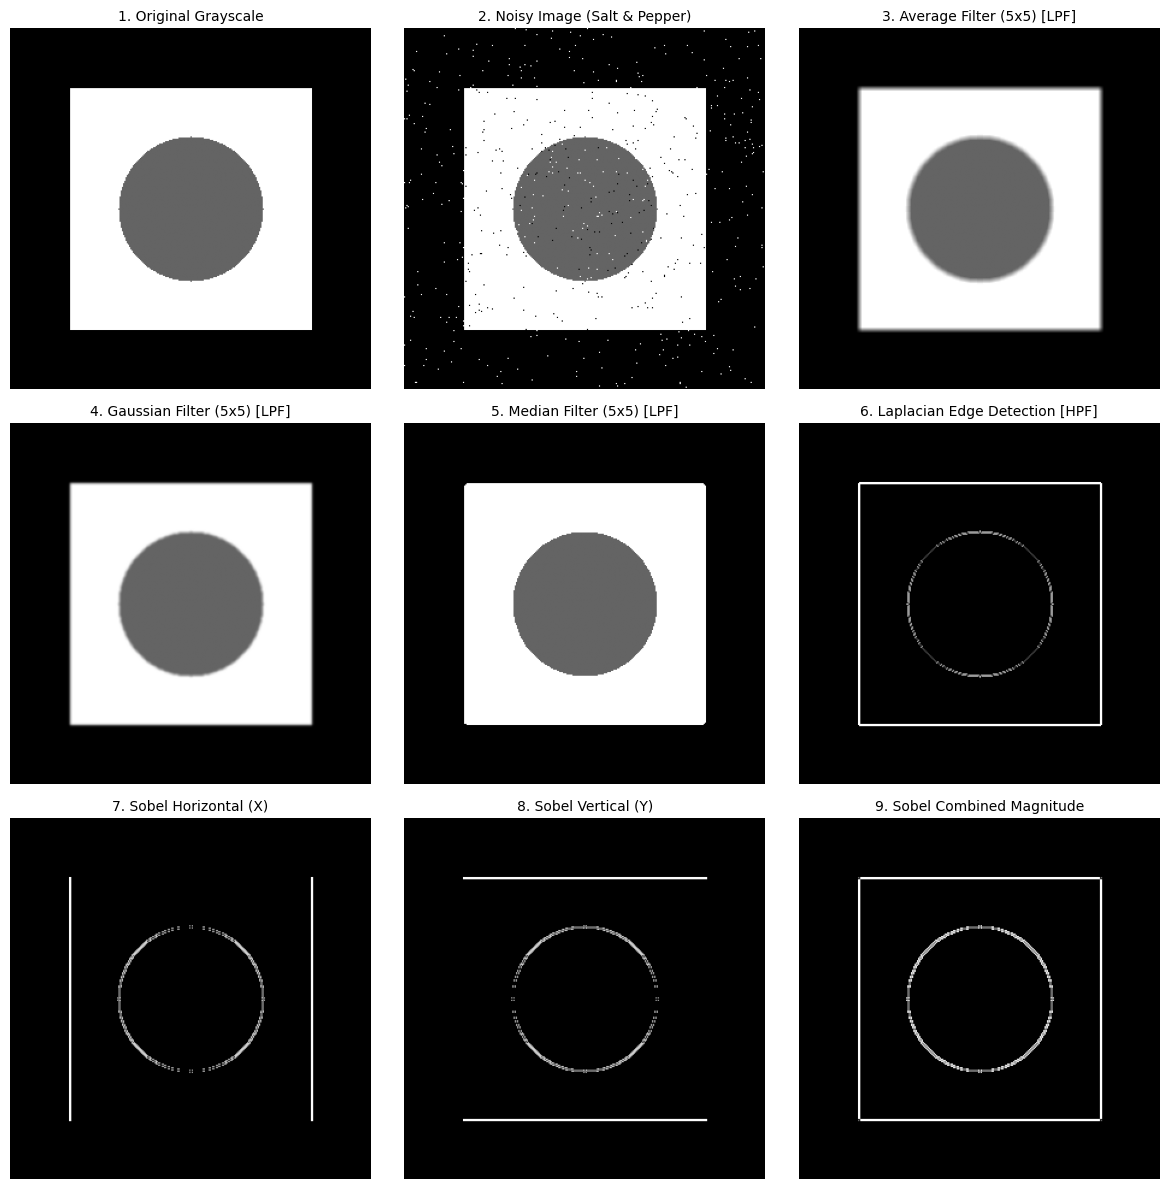

Name-Manas Devputra
CU24250160


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load Original Image
image_path = 'sample_image.jpg'  # Replace with your image file path
img = cv2.imread(image_path)

if img is None:
    # Generate a synthetic sample image with shapes if no image is loaded
    img = np.zeros((300, 300, 3), dtype=np.uint8)
    cv2.rectangle(img, (50, 50), (250, 250), (255, 255, 255), -1)
    cv2.circle(img, (150, 150), 60, (100, 100, 100), -1)

# Convert to grayscale for standard spatial filtering processing
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Add Salt-and-Pepper Noise for demonstration
noisy_img = gray_img.copy()
num_noise = 1000
# Salt (white pixels)
coords = [np.random.randint(0, i - 1, int(num_noise / 2)) for i in gray_img.shape]
noisy_img[tuple(coords)] = 255
# Pepper (black pixels)
coords = [np.random.randint(0, i - 1, int(num_noise / 2)) for i in gray_img.shape]
noisy_img[tuple(coords)] = 0

# --- LOW-PASS FILTERS (Smoothing & Noise Removal) ---
# 1. Average Filter
avg_blur = cv2.blur(gray_img, (5, 5))

# 2. Gaussian Filter
gaussian_blur = cv2.GaussianBlur(gray_img, (5, 5), 0)

# 3. Median Filter (Applied on salt-and-pepper noise image)
median_filtered = cv2.medianBlur(noisy_img, 5)

# --- HIGH-PASS FILTERS (Edge Detection & Feature Enhancement)[cite: 1] ---
# 1. Laplacian Filter[cite: 1]
laplacian = cv2.Laplacian(gray_img, cv2.CV_64F)
laplacian = np.uint8(np.absolute(laplacian))

# 2. Sobel Operators (Horizontal and Vertical)[cite: 1]
sobel_x = cv2.Sobel(gray_img, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray_img, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = cv2.magnitude(sobel_x, sobel_y)
sobel_combined = np.uint8(sobel_combined)

# --- VISUALIZATION[cite: 1] ---
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
axes = axes.ravel()

images = [
    (gray_img, "1. Original Grayscale"),
    (noisy_img, "2. Noisy Image (Salt & Pepper)"),
    (avg_blur, "3. Average Filter (5x5) [LPF]"),
    (gaussian_blur, "4. Gaussian Filter (5x5) [LPF]"),
    (median_filtered, "5. Median Filter (5x5) [LPF]"),
    (laplacian, "6. Laplacian Edge Detection [HPF]"),
    (np.uint8(np.absolute(sobel_x)), "7. Sobel Horizontal (X)"),
    (np.uint8(np.absolute(sobel_y)), "8. Sobel Vertical (Y)"),
    (sobel_combined, "9. Sobel Combined Magnitude")
]

for i, (image, title) in enumerate(images):
    axes[i].imshow(image, cmap='gray')
    axes[i].set_title(title, fontsize=10)
    axes[i].axis('off')

plt.tight_layout()
plt.show()
print("Name-Manas Devputra")
print("CU24250160")

1. **Spatial Filtering and Its Role in Digital Image Processing**
   
   Spatial filtering is an image processing technique where operations are performed directly on the pixel values of an image based on the values of adjacent neighboring pixels. It utilizes a small matrix called a kernel or filter mask, which slides across the image to calculate a new intensity value for each central pixel using convolution.  


   In digital image processing, it is used for:

   **Noise Reduction**: Smoothing out unwanted background noise or random pixel variations.  


   **Image Smoothing**: Softening sharp edges or blending pixel intensities.  


   **Edge Detection & Sharpening**: Highlighting structural boundaries, textures, and fine details.  


   **Feature Extraction**: Preparing images as a preprocessing step for object detection and computer vision tasks.





2. Low-Pass Filters (LPF) vs. High-Pass Filters (HPF)
Feature	Low-Pass Filters (LPF)	High-Pass Filters (HPF)
Primary Purpose
Image smoothing and noise removal  


   Edge enhancement and detail extraction.  

   Frequency Handling
   Allows low-frequency components (smooth background areas) to pass, suppressing high frequencies.  


   Allows high-frequency components (sharp intensity changes) to pass, suppressing low frequencies.  


   Visual Effect
   Blurs the image, reducing sharp transitions.  


   Enhances image sharp boundaries and edges.  


   Kernel Sum	The elements typically sum to 1 (to maintain overall image brightness).	The elements typically sum to 0 (rescaling flat regions to zero intensity).
   Examples
   Average Filter, Gaussian Blur, Median Filter.  
   Laplacian Filter, Sobel Filter, Unsharp Masking.  


3. Comparison of Smoothing Filters
Average (Mean) Filter:

  Working Principle: Replaces the target pixel's value with the arithmetic mean of all pixels in its local neighborhood.  

  Applications: General noise reduction where uniform blurring is acceptable.  


   Gaussian Filter:

   Working Principle: Uses a weighted average where pixels closer to the center of the kernel are given higher weight, following a 2D Gaussian distribution.  


   Applications: Smoothing and removing Gaussian noise while better maintaining structural edges compared to average filtering.  


   Median Filter:

   Working Principle: Replaces the target pixel's value with the median value of all pixels in its neighborhood after sorting them.  


   Applications: Removing salt-and-pepper (impulse) noise without blurring sharp object edges.  


4. Effectiveness of Median Filter for Salt-and-Pepper Noise
Salt-and-pepper noise introduces isolated pixel values that are either extreme highs (white/salt) or extreme lows (black/pepper).

Mean or Gaussian filters average these extreme values into neighboring pixels, causing the noise to spread as blurry patches. In contrast, the Median Filter sorts pixel values in the kernel neighborhood. Because extreme noise values fall at the far ends (0 or 255) of the sorted list, the central value (median) selected is almost guaranteed to be a valid surrounding pixel value rather than a noise artifact.

5. Role of Convolution Kernels in Spatial Filtering
Convolution kernels act as a spatial template defining the mathematical operation applied to neighboring pixels.  


A convolution kernel is a small 2D matrix (e.g., 3×3, 5×5) containing specific weights.  


As the kernel moves over the image pixel-by-pixel, each overlapping image value is multiplied by its corresponding kernel weight, and the results are summed up to generate a new intensity value.  


The specific configuration of weights inside the kernel directly determines the outcome—such as blurring, sharpening, or directional edge detection.  


6. Purpose of Sobel and Laplacian Operators in Edge Detection
Sobel Operator: A 1st-order derivative operator that computes approximate intensity gradients along specific directions (horizontal G
x
​
  and vertical G
y
​
 ). It helps locate edges along with their orientation/direction.  


Laplacian Operator: A 2nd-order derivative isotropic filter that detects rapid intensity changes regardless of direction. It produces thin edges and is often combined with a smoothing step (Laplacian of Gaussian) or added back to the original image to sharpen details.  

7. Why Spatial Filtering is Essential for Preprocessing
Raw image data captured from hardware sensors often contains random noise, poor contrast, or artifacts caused by environmental conditions. Spatial filtering serves as an essential preliminary step because high-level computer vision algorithms (such as contour extraction, object segmentation, or keypoint tracking) depend on reliable image gradients. Preprocessing cleans up noise and accentuates structural features, significantly increasing the precision and reliability of downstream algorithms.  


8. Trade-off Between Image Smoothing and Edge Preservation
The Smoothing Dilemma: Removing image noise typically involves suppressing high-frequency components. However, sharp edges and fine structural details are also composed of high-frequency components.

The Trade-off: Excessive smoothing reduces noise but blurs essential edges, losing sharp boundaries. Conversely, weak filtering preserves precise edges but leaves noise intact. Advanced filters (such as bilateral or median filters) attempt to bridge this trade-off by preserving edges while smoothing homogeneous noise regions.  


9. Four Real-World Applications of Spatial Filtering
Medical Imaging: Sharpening MRI/CT scan details to highlight anatomical structures and detecting tumors.  


Autonomous Systems / Self-Driving Vehicles: Detecting lane markings, pedestrian borders, and road obstacles via edge filters (Sobel).  


Surveillance Systems: Enhancing low-contrast, noisy security camera feeds for license plate and face identification.  


Remote Sensing & Satellite Imagery: Delineating coastline contours, river paths, and urban infrastructure boundaries from satellite observations.  


10. Spatial Domain vs. Frequency Domain Filtering
Feature	Spatial Domain Filtering	Frequency Domain Filtering
Operation Place
Directly operates on image pixel values using standard convolution masks.  


Operates on the Fourier Transform (frequency spectrum) of the image.
Mathematical Tool
2D Spatial Convolution.  


Discrete Fourier Transform (DFT / FFT) followed by multiplication and Inverse DFT.
Computational Complexity	Highly efficient for small kernel sizes (3×3, 5×5).	More efficient for large global operations or broad frequency selection.
Ease of Implementation
Straightforward, intuitive local pixel updates.  


Requires transformation to/from frequency space and complex multiplication.
Practical Use
Real-time local processing, edge detection, simple smoothing.  


Periodic noise removal, global band-pass filtering, compression.